```
Прогнозирование вероятности дефолта (PD)

В связи с отсутствием публично доступных данных о кредитных дефолтах,
для демонстрации методологии кредитного скоринга используется публичный
датасет аномальных финансовых транзакций (creditcard.csv).

Переменная Class:
- Class = 1 интерпретируется как событие дефолта
- Class = 0 — отсутствие дефолта

Задача формулируется как бинарная классификация с сильным дисбалансом классов.
Цель — оценка вероятности дефолта (Probability of Default, PD).

```

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("creditcard.csv")
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
df.isnull().sum().sum()

np.int64(0)

# Распределение классов

In [5]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [6]:
df['Class'].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

# Формирование признаков и целевой переменной

In [7]:
X = df.drop(columns=['Class'])
y = df['Class']

# Обучение

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)


# Масштабирование признаков

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Учёт дисбаланса классов

In [10]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
scale_pos_weight

np.float64(578.546511627907)

# Обучение модели XGBoost

In [11]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

model.fit(X_train_scaled, y_train)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'auc'


# Оценка качества модели

In [12]:
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]


In [13]:
print(classification_report(y_test, y_pred, digits=4))


              precision    recall  f1-score   support

           0     0.9997    0.9992    0.9994     85295
           1     0.6308    0.8311    0.7172       148

    accuracy                         0.9989     85443
   macro avg     0.8152    0.9151    0.8583     85443
weighted avg     0.9991    0.9989    0.9989     85443



In [14]:
roc_auc_score(y_test, y_proba)

0.9747927304759476

# ROC-кривая

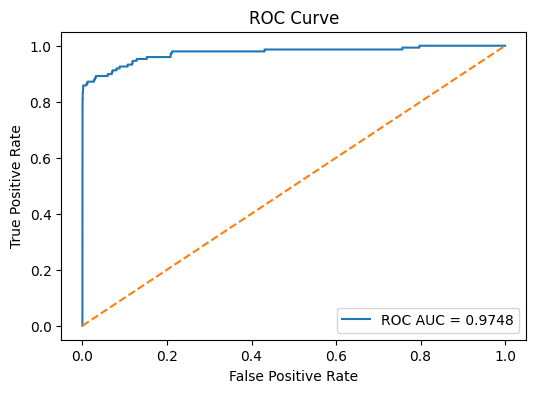

In [15]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'ROC AUC = {roc_auc_score(y_test, y_proba):.4f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


# Получение вероятности дефолта (PD)

In [16]:
pd_results = X_test.copy()
pd_results['PD'] = y_proba
pd_results['Actual'] = y_test.values

pd_results.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,PD,Actual
186882,127294.0,-2.537331,1.890864,-0.840555,-1.102759,-2.105725,0.367811,-2.737844,-3.543314,-0.483147,...,-2.167329,1.022567,-0.241143,-1.094885,-0.475427,-0.177157,-0.082691,37.40,0.000048,0
165754,117632.0,-0.250839,1.104108,0.206089,0.417324,1.204079,-0.350694,1.369769,-0.133535,-0.957100,...,0.499501,-0.392572,-0.393364,0.233354,-0.490717,0.143897,0.136810,9.27,0.000372,0
235285,148330.0,0.568980,-2.520416,-1.114138,1.670652,-1.128945,0.398822,0.190403,0.161493,0.840595,...,-0.760732,-0.181332,0.595866,-0.760920,-1.048927,-0.096970,0.088686,700.00,0.010702,0
101271,67778.0,1.328892,0.226908,-0.308968,0.381772,0.238490,-0.282946,0.029460,-0.079962,0.227173,...,-1.148959,-0.047403,-1.074464,0.375683,0.182045,-0.031732,0.017501,14.99,0.000489,0
5832,6308.0,1.124863,-0.165691,1.337053,1.030033,-0.891116,0.202926,-0.825094,0.163280,2.301808,...,-0.195607,0.072785,0.045625,0.135192,0.308617,0.001142,0.017673,17.25,0.000403,0


# Cut-off стратегия принятия решения

In [17]:
cutoff = 0.2

pd_results['Decision'] = (pd_results['PD'] >= cutoff).astype(int)
pd_results[['PD', 'Decision', 'Actual']].head()


,PD,Decision,Actual
186882,0.000048,0,0
165754,0.000372,0,0
235285,0.010702,0,0
101271,0.000489,0,0
5832,0.000403,0,0


# Важность признаков

In [18]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

feature_importance.head(10)


,Feature,Importance
14,V14,0.306077
10,V10,0.154723
4,V4,0.090551
20,V20,0.032977
12,V12,0.028509
17,V17,0.027966
29,Amount,0.025997
8,V8,0.023562
21,V21,0.023444
11,V11,0.022669


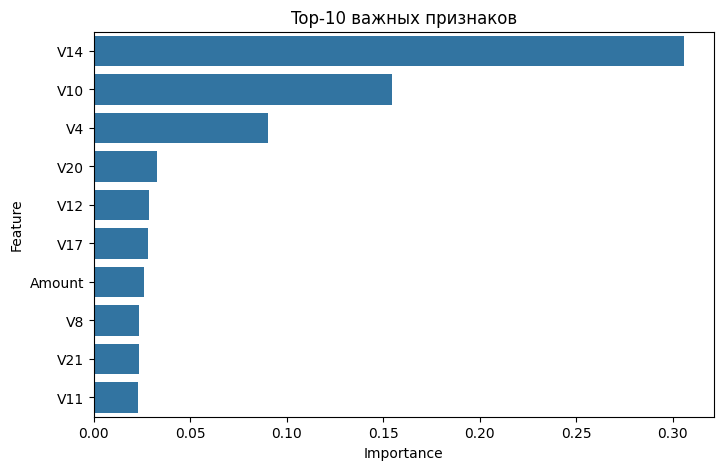

In [19]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)
plt.title('Top-10 важных признаков')
plt.show()


Построена модель оценки вероятности дефолта (PD) на основе алгоритма XGBoost.
Модель демонстрирует высокую способность ранжирования риска (ROC AUC > 0.9),
что соответствует требованиям к скоринговым моделям.

Полученные вероятности PD могут использоваться для:
- определения кредитных cut-off
- расчёта Expected Loss
- сегментации клиентов по уровню риска